In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [32]:
# 2. Download NLTK resources
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("NLTK resources are ready.")


NLTK resources are ready.


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Lenovo\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [39]:
df = pd.read_csv("sentiment_reviews.csv")

print("Dataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 10 Records:")
display(df.head(10))

print("\nDataset Information:")
df.info()

Dataset loaded successfully!

Dataset Shape:
(10, 3)

First 10 Records:


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    10 non-null     int64 
 1   review_text  10 non-null     object
 2   sentiment    10 non-null     object
dtypes: int64(1), object(2)
memory usage: 368.0+ bytes


In [40]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nUnique Sentiment Labels:")
print(df["sentiment"].unique())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

Column Names:
['review_id', 'review_text', 'sentiment']

Data Types:
review_id       int64
review_text    object
sentiment      object
dtype: object

Missing Values:
review_id      0
review_text    0
sentiment      0
dtype: int64

Duplicate Records:
0

Unique Sentiment Labels:
['positive' 'negative' 'neutral']

Sentiment Distribution:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


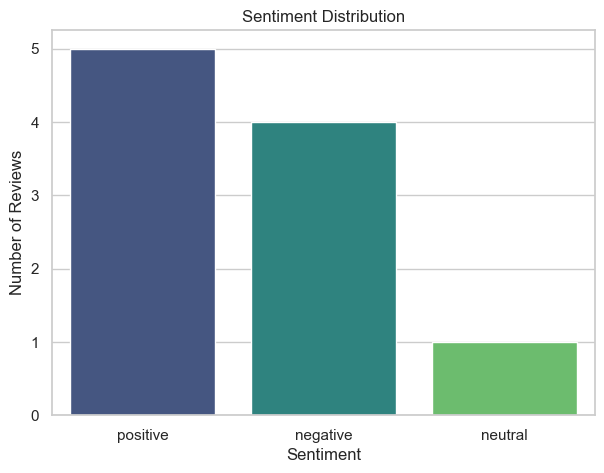

In [43]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    order=["positive", "negative", "neutral"],
    palette="viridis",
    legend=False
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [44]:
import nltk

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

wordnet_available = False

try:
    nltk.data.find("corpora/wordnet")
    wordnet_available = True

except LookupError:
    try:
        wordnet_available = nltk.download(
            "wordnet",
            quiet=True
        )

        
        nltk.data.find("corpora/wordnet")
        wordnet_available = True

    except Exception:
        wordnet_available = False

if wordnet_available:
    print("WordNet lemmatization enabled.")
else:
    print("WordNet unavailable. Using safe fallback without lemmatization.")

WordNet unavailable. Using safe fallback without lemmatization.


In [46]:
stop_words = ENGLISH_STOP_WORDS.difference({
    "no",
    "not",
    "nor",
    "never",
    "none"
})

def preprocess_text(text):

    if not isinstance(text, str):
        raise TypeError("Review must be a string.")


    text = text.lower()

    text = re.sub(r"<[^>]+>", " ", text)

    tokens = re.findall(r"[a-z]+", text)

    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    if wordnet_available:

        processed_tokens = []

        for word in tokens:
            try:
                processed_tokens.append(
                    lemmatizer.lemmatize(word)
                )

            except LookupError:
                processed_tokens.append(word)

        tokens = processed_tokens

    return " ".join(tokens)

In [47]:
sample_review = df["review_text"].iloc[0]

print("Original Review:")
print(sample_review)

print("\nProcessed Review:")
print(preprocess_text(sample_review))

Original Review:
The product quality is exceptional, exceeded all my expectations!

Processed Review:
product quality exceptional exceeded expectations


In [48]:
X = df["review_text"].copy()

y = df["sentiment"].copy()

print("Input Features:")
print(X.head())

print("\nTarget Labels:")
print(y.head())

print("\nUnique Classes:")
print(y.unique())

print("\nNumber of Records:", len(X))

Input Features:
0    The product quality is exceptional, exceeded a...
1    Terrible customer service and the item arrived...
2    Average performance, decent for the price poin...
3    Absolutely love this! Easy to setup, robust, a...
4    Stopped working after two days. Extremely disa...
Name: review_text, dtype: object

Target Labels:
0    positive
1    negative
2     neutral
3    positive
4    negative
Name: sentiment, dtype: object

Unique Classes:
['positive' 'negative' 'neutral']

Number of Records: 10


In [49]:
tfidf = TfidfVectorizer(
    preprocessor=preprocess_text,
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    max_features=5000,
    ngram_range=(1, 2)
)

print("TF-IDF vectorizer configured successfully.")

TF-IDF vectorizer configured successfully.


In [50]:
positive_indices = df.index[
    df["sentiment"] == "positive"
].tolist()

negative_indices = df.index[
    df["sentiment"] == "negative"
].tolist()

if len(positive_indices) < 2 or len(negative_indices) < 2:
    raise ValueError(
        "Not enough positive and negative records "
        "for the demonstration split."
    )

# Select one positive and one negative review for testing
test_indices = [
    positive_indices[0],
    negative_indices[0]
]

# Remaining records are used for training
train_indices = [
    idx for idx in df.index
    if idx not in test_indices
]

X_train = X.loc[train_indices]
X_test = X.loc[test_indices]

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training records: 8
Testing records: 2

Training sentiment distribution:
sentiment
positive    4
negative    3
neutral     1
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
positive    1
negative    1
Name: count, dtype: int64


In [51]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF transformation completed!")

print("\nTraining Matrix Shape:")
print(X_train_tfidf.shape)

print("\nTesting Matrix Shape:")
print(X_test_tfidf.shape)

print("\nVocabulary Size:")
print(len(tfidf.vocabulary_))

TF-IDF transformation completed!

Training Matrix Shape:
(8, 94)

Testing Matrix Shape:
(2, 94)

Vocabulary Size:
94


In [52]:
nb_model = MultinomialNB()

nb_model.fit(
    X_train_tfidf,
    y_train
)

print("Multinomial Naive Bayes trained successfully!")

Multinomial Naive Bayes trained successfully!


In [53]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_tfidf,
    y_train
)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [54]:
nb_predictions = nb_model.predict(X_test_tfidf)

print("MULTINOMIAL NAIVE BAYES RESULTS")

print("\nAccuracy:")
print(accuracy_score(y_test, nb_predictions))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        nb_predictions,
        labels=["negative", "neutral", "positive"],
        zero_division=0
    )
)

MULTINOMIAL NAIVE BAYES RESULTS

Accuracy:
0.5

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
     neutral       0.00      0.00      0.00         0
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.17      0.33      0.22         2
weighted avg       0.25      0.50      0.33         2



In [55]:
lr_predictions = lr_model.predict(X_test_tfidf)

print("LOGISTIC REGRESSION RESULTS")

print("\nAccuracy:")
print(accuracy_score(y_test, lr_predictions))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        lr_predictions,
        labels=["negative", "neutral", "positive"],
        zero_division=0
    )
)

LOGISTIC REGRESSION RESULTS

Accuracy:
0.5

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
     neutral       0.00      0.00      0.00         0
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.17      0.33      0.22         2
weighted avg       0.25      0.50      0.33         2



                     Model  Accuracy
0  Multinomial Naive Bayes       0.5
1      Logistic Regression       0.5


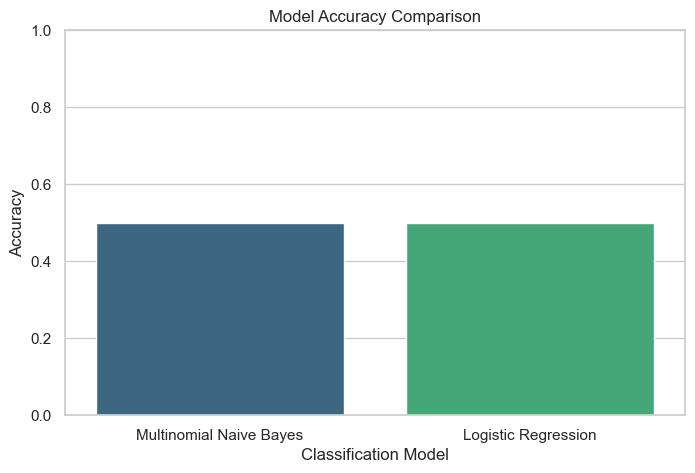

In [56]:
results = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression"
    ],

    "Accuracy": [
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, lr_predictions)
    ]
})

print(results)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy",
    hue="Model",
    legend=False,
    palette="viridis"
)

plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Classification Model")
plt.show()

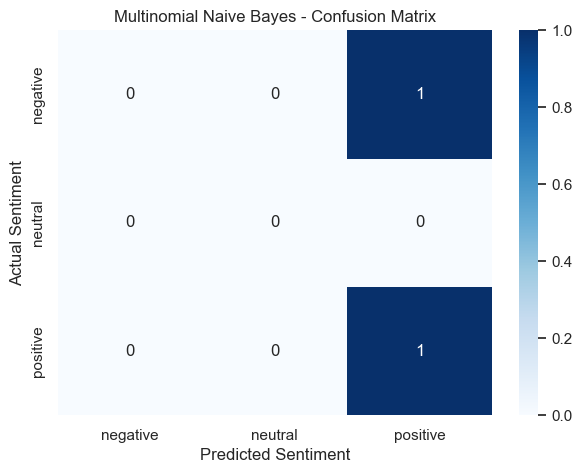

In [57]:
labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(
    y_test,
    nb_predictions,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Multinomial Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [58]:
final_tfidf = TfidfVectorizer(
    preprocessor=preprocess_text,
    tokenizer=str.split,
    token_pattern=None,
    lowercase=False,
    max_features=5000,
    ngram_range=(1, 2)
)

final_X = final_tfidf.fit_transform(X)

final_model = MultinomialNB()

final_model.fit(
    final_X,
    y
)

print("Final model trained successfully!")

print("\nRecords used:", len(X))
print("Learned classes:", final_model.classes_)
print("TF-IDF vocabulary size:", len(final_tfidf.vocabulary_))

Final model trained successfully!

Records used: 10
Learned classes: ['negative' 'neutral' 'positive']
TF-IDF vocabulary size: 115


In [59]:
def predict_sentiment(review):

    if not isinstance(review, str):
        raise TypeError("Please enter text as a string.")

    if not review.strip():
        raise ValueError("Review cannot be empty.")

    # Transform input using the trained vectorizer
    review_vector = final_tfidf.transform([review])

    # Predict sentiment
    prediction = final_model.predict(review_vector)[0]

    # Calculate class probabilities
    probabilities = final_model.predict_proba(
        review_vector
    )[0]

    print("\nCustomer Review:")
    print(review)

    print("\nPredicted Sentiment:")
    print(prediction.upper())

    print("\nClass Probabilities:")

    for label, probability in zip(
        final_model.classes_,
        probabilities
    ):
        print(f"{label}: {probability * 100:.2f}%")

    return prediction

### The NLP Sentiment Classification project successfully demonstrates the use of Natural Language Processing and Machine Learning to classify customer reviews into positive, negative, and neutral sentiments. Text preprocessing and TF-IDF vectorization convert raw reviews into numerical features, which are used to train Multinomial Naive Bayes and Logistic Regression models. Their performance is evaluated using accuracy, classification reports, and confusion matrices. An interactive prediction function is also developed to classify new customer reviews. Thus, the project provides a basic end-to-end sentiment analysis pipeline.